# Training size and feature-selection cost

Hold out 20,000 validation rows from the original training split. Draw stratified
training samples of 5,000, 10,000, 30,000, 60,000, and 120,000 rows using seeds 0–2.
Use the fixed MODEL_SPECS parameters with 17 or 33 original features for every model.
The original test rows are never returned or evaluated.

MI is computed once per sample and its measured time is charged to each k=17 run.
Each classifier refits its own preprocessing. Predictions use all 20,000 validation
rows at threshold 0.5. Totals include MI, preprocessing, fit, and predict_proba.

## 1. Environment and training-only validation split

In [1]:
from pathlib import Path
from itertools import product
import hashlib
import json
import platform
import sys
import time
import warnings

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_info, threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=1)
cwd = Path.cwd()
repo_root = cwd if (cwd / "src/unsupervised_common.py").exists() else cwd.parent
assert (repo_root / "src/unsupervised_common.py").exists(), "Open from the repository root or notebooks/."
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import build_preprocessor
from unsupervised_common import (
    MODEL_SPECS, load_training_data, rank_features_by_mi,
    make_classifier, classification_metrics,
)
results_dir = repo_root / "results"
results_dir.mkdir(exist_ok=True)
N_VALUES = [5_000, 10_000, 30_000, 60_000, 120_000]
SEEDS = [0, 1, 2]
FEATURE_COUNTS = [17, 33]
MODELS = list(MODEL_SPECS)
TIME_COLUMNS = ["MI_seconds", "preprocessing_seconds", "fit_seconds", "predict_seconds", "total_seconds"]
protected_paths = [p for folder in ["notebooks", "scripts", "src", "results"]
                   for p in (repo_root / folder).iterdir() if p.is_file()
                   and not p.name.startswith(("10_training_size", "build_training_size", "trainsize_"))]
protected_paths.append(repo_root / "requirements.txt")
input_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in protected_paths}
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
data = load_training_data(repo_root)
X_pool, X_valid, y_pool, y_valid = train_test_split(
    data.X_train, data.y_train, test_size=20_000, stratify=data.y_train, random_state=42
)
training_ids = set(data.X_train.index)
validation_ids = set(X_valid.index)
assert len(data.X_train) == 172_459 and len(X_pool) == 152_459 and len(X_valid) == 20_000
assert set(X_pool.index).isdisjoint(validation_ids)
assert set(X_pool.index) | validation_ids == training_ids
assert validation_ids.issubset(training_ids)
assert data.X_train.shape[1] == 33
validation_index_sha256 = hashlib.sha256(X_valid.index.to_numpy(dtype=np.int64).tobytes()).hexdigest()
print(f"Training pool: {len(X_pool):,}; fixed validation rows: {len(X_valid):,}")
display(pd.DataFrame([{"model": name, "params": json.dumps(spec["params"]),
                       "feature_counts": str(FEATURE_COUNTS)} for name, spec in MODEL_SPECS.items()]))

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4


Training pool: 152,459; fixed validation rows: 20,000


,model,params,feature_counts
0,Random Forest,"{""n_estimators"": 400, ""max_depth"": 20, ""min_sa...","[17, 33]"
1,GaussianNB,"{""var_smoothing"": 1e-06}","[17, 33]"
2,Logistic Regression,"{""C"": 0.1, ""random_state"": 42, ""max_iter"": 100}","[17, 33]"
3,k-NN,"{""n_neighbors"": 51, ""weights"": ""uniform"", ""n_j...","[17, 33]"


## 2. Fit policy and checkpoints

LR starts at max_iter=100 for each run. As in notebook 04, a convergence warning
triggers a fresh fit with twice the limit, up to 25,600. Fit time includes all
attempts. Captured warnings and iteration limits are saved without changing
other parameters. One progress line is printed per completed condition.
Membership in the canonical X_train excludes the original test rows.

In [2]:
records, sample_records, ranking_records = [], [], []
fit_attempts, warning_records = [], []
WARNING_COLUMNS = ["N", "random_state", "k", "model", "max_iter", "category", "message"]

def checkpoint():
    if records:
        pd.DataFrame(records).to_csv(results_dir / "trainsize_runs.csv", index=False)
    if sample_records:
        pd.DataFrame(sample_records).to_csv(results_dir / "trainsize_samples.csv", index=False)
    if ranking_records:
        pd.concat(ranking_records, ignore_index=True).to_csv(results_dir / "trainsize_mi_rankings.csv", index=False)
    if fit_attempts:
        pd.DataFrame(fit_attempts).to_csv(results_dir / "trainsize_fit_attempts.csv", index=False)
    pd.DataFrame(warning_records, columns=WARNING_COLUMNS).to_csv(
        results_dir / "trainsize_warnings.csv", index=False
    )

def fit_with_retries(model_name, Z_fit, y_fit, context):
    model = make_classifier(model_name)
    started = time.perf_counter()
    attempts, convergence_count, warning_count = 0, 0, 0
    while True:
        attempt_started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(Z_fit, y_fit)
        attempt_seconds = time.perf_counter() - attempt_started
        limit = model.get_params().get("max_iter")
        convergence = any(issubclass(item.category, ConvergenceWarning) for item in caught)
        attempts += 1
        convergence_count += int(convergence)
        warning_count += len(caught)
        fit_attempts.append({**context, "attempt": attempts, "max_iter": limit,
                             "seconds": attempt_seconds, "convergence_warning": convergence})
        for item in caught:
            warning_records.append({**context, "max_iter": limit,
                                    "category": item.category.__name__, "message": str(item.message)})
        if not convergence:
            break
        if model_name != "Logistic Regression" or limit >= 25_600:
            checkpoint()
            raise RuntimeError(f"Unresolved convergence warning: {context}")
        model = make_classifier(model_name)
        model.set_params(max_iter=limit * 2)
    return model, time.perf_counter() - started, attempts, convergence_count, warning_count

## 3. Runs in increasing training-size order

In [3]:
for N in N_VALUES:
    for seed in SEEDS:
        X_fit, _, y_fit, _ = train_test_split(
            X_pool, y_pool, train_size=N, stratify=y_pool, random_state=seed
        )
        fit_ids = set(X_fit.index)
        assert len(X_fit) == N and X_fit.index.is_unique
        assert fit_ids.issubset(training_ids) and fit_ids.isdisjoint(validation_ids)
        assert np.isclose(y_fit.mean(), y_pool.mean(), atol=1 / N, rtol=0)
        started = time.perf_counter()
        ranking = rank_features_by_mi(X_fit, y_fit)
        selected17 = ranking["feature"].head(17).tolist()
        sample_MI_seconds = time.perf_counter() - started
        sample_records.append({
            "N": N, "random_state": seed, "sample_count": len(X_fit),
            "sample_positive_count": int(y_fit.sum()), "sample_positive_rate": y_fit.mean(),
            "pool_positive_rate": y_pool.mean(), "rate_tolerance": 1 / N,
            "validation_count": len(X_valid), "validation_overlap": len(fit_ids & validation_ids),
            "training_membership_verified": fit_ids.issubset(training_ids),
            "sample_index_sha256": hashlib.sha256(X_fit.index.to_numpy(dtype=np.int64).tobytes()).hexdigest(),
            "validation_index_sha256": validation_index_sha256,
            "MI_seconds": sample_MI_seconds, "selected_features_k17": json.dumps(selected17),
        })
        ranking_records.append(ranking.assign(N=N, random_state=seed, rank=range(1, 34)))
        checkpoint()
        for k in FEATURE_COUNTS:
            selected = selected17 if k == 17 else list(X_fit.columns)
            mi_seconds = sample_MI_seconds if k == 17 else 0.0
            for model_name in MODELS:
                X_fit_k, X_valid_k = X_fit[selected], X_valid[selected]
                preprocessor = build_preprocessor(X_fit_k, log_money=False)
                started = time.perf_counter()
                Z_fit = preprocessor.fit_transform(X_fit_k)
                Z_valid = preprocessor.transform(X_valid_k)
                if model_name == "GaussianNB" and hasattr(Z_fit, "toarray"):
                    Z_fit, Z_valid = Z_fit.toarray(), Z_valid.toarray()
                preprocessing_seconds = time.perf_counter() - started
                context = {"N": N, "random_state": seed, "k": k, "model": model_name}
                model, fit_seconds, attempts, convergence_count, warning_count = fit_with_retries(
                    model_name, Z_fit, y_fit, context
                )
                started = time.perf_counter()
                probability = model.predict_proba(Z_valid)[:, 1]
                predict_seconds = time.perf_counter() - started
                total_seconds = mi_seconds + preprocessing_seconds + fit_seconds + predict_seconds
                records.append({
                    **context, "training_count": len(X_fit), "validation_count": len(X_valid),
                    "sample_positive_rate": y_fit.mean(), "validation_positive_rate": y_valid.mean(),
                    "MI_seconds": mi_seconds, "preprocessing_seconds": preprocessing_seconds,
                    "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
                    "total_seconds": total_seconds, **classification_metrics(y_valid, probability),
                    "encoded_features": Z_fit.shape[1], "selected_features": json.dumps(selected),
                    "max_iter": model.get_params().get("max_iter"), "fit_attempts": attempts,
                    "convergence_warning_count": convergence_count, "fit_warning_count": warning_count,
                    "validation_index_sha256": validation_index_sha256,
                })
                checkpoint()
                print(f"[{len(records)}/120] N={N}, seed={seed}, k={k}, {model_name}: "
                      f"AP={records[-1]['AP']:.6f}, total={total_seconds:.3f}s, "
                      f"max_iter={records[-1]['max_iter']}, attempts={attempts}", flush=True)
runs = pd.DataFrame(records)
samples = pd.DataFrame(sample_records)
checkpoint()
print(f"Captured fit diagnostics: {len(warning_records)}")

[1/120] N=5000, seed=0, k=17, Random Forest: AP=0.580198, total=1.610s, max_iter=None, attempts=1


[2/120] N=5000, seed=0, k=17, GaussianNB: AP=0.159774, total=0.208s, max_iter=None, attempts=1


[3/120] N=5000, seed=0, k=17, Logistic Regression: AP=0.576775, total=0.165s, max_iter=100, attempts=1


[4/120] N=5000, seed=0, k=17, k-NN: AP=0.519501, total=1.772s, max_iter=None, attempts=1


[5/120] N=5000, seed=0, k=33, Random Forest: AP=0.581450, total=2.093s, max_iter=None, attempts=1


[6/120] N=5000, seed=0, k=33, GaussianNB: AP=0.105490, total=0.184s, max_iter=None, attempts=1


... (111 outputs left out)

[118/120] N=120000, seed=2, k=33, GaussianNB: AP=0.152288, total=0.991s, max_iter=None, attempts=1


[119/120] N=120000, seed=2, k=33, Logistic Regression: AP=0.626515, total=0.888s, max_iter=100, attempts=1


[120/120] N=120000, seed=2, k=33, k-NN: AP=0.594939, total=49.074s, max_iter=None, attempts=1


Captured fit diagnostics: 1


## 4. Three-seed summaries and paired time ratios

Each ratio is computed within the same training size, sample seed, and model
before aggregation. MI-to-fit/predict divides k=17 MI time by its fit plus
predict time. Strict comparisons to 1 classify the three paired ratios.

In [4]:
summary_columns = TIME_COLUMNS + ["AP", "ROC_AUC", "F1"]
summary = runs.groupby(["N", "k", "model"])[summary_columns].agg(["mean", "min", "max"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.to_csv(results_dir / "trainsize_summary.csv", index=False)
pair_columns = ["N", "random_state", "model", "total_seconds", "MI_seconds", "fit_seconds", "predict_seconds"]
paired = runs.loc[runs.k == 17, pair_columns].merge(
    runs.loc[runs.k == 33, pair_columns], on=["N", "random_state", "model"],
    suffixes=("_17", "_33"), validate="one_to_one"
)
paired["total_ratio"] = paired.total_seconds_17 / paired.total_seconds_33
paired["MI_over_fit_predict_ratio"] = paired.MI_seconds_17 / (paired.fit_seconds_17 + paired.predict_seconds_17)
paired.to_csv(results_dir / "trainsize_paired_ratios.csv", index=False)
ratio = paired.groupby(["N", "model"])[["total_ratio", "MI_over_fit_predict_ratio"]].agg(["mean", "min", "max"])
ratio.columns = [f"{metric}_{stat}" for metric, stat in ratio.columns]
ratio = ratio.reset_index()
status_rows = []
for (N, model_name), group in paired.groupby(["N", "model"]):
    values = group.total_ratio.to_numpy()
    status = ("all below 1" if (values < 1).all() else
              "all above 1" if (values > 1).all() else "mixed or equal")
    status_rows.append({"N": N, "model": model_name, "repetitions": len(group),
                        "ratio_status": status, "ratios_below_1": int((values < 1).sum()),
                        "ratios_above_1": int((values > 1).sum()), "ratios_equal_1": int((values == 1).sum())})
ratio = ratio.merge(pd.DataFrame(status_rows), on=["N", "model"], validate="one_to_one")
ratio.to_csv(results_dir / "trainsize_ratio.csv", index=False)
mi_summary = samples.groupby("N").agg(MI_seconds_mean=("MI_seconds", "mean"),
                                      MI_seconds_min=("MI_seconds", "min"),
                                      MI_seconds_max=("MI_seconds", "max"),
                                      repetitions=("MI_seconds", "size")).reset_index()
mi_summary.to_csv(results_dir / "trainsize_mi_summary.csv", index=False)
display(summary.round(6))
display(ratio.round(6))
display(mi_summary.round(6))

,N,k,model,MI_seconds_mean,MI_seconds_min,MI_seconds_max,preprocessing_seconds_mean,preprocessing_seconds_min,preprocessing_seconds_max,fit_seconds_mean,...,total_seconds_max,AP_mean,AP_min,AP_max,ROC_AUC_mean,ROC_AUC_min,ROC_AUC_max,F1_mean,F1_min,F1_max
0,5000,17,GaussianNB,0.114696,0.104582,0.126089,0.057192,0.049108,0.064357,0.006950,...,0.216300,0.147189,0.140796,0.159774,0.712628,0.699237,0.736671,0.239854,0.237758,0.241499
1,5000,17,Logistic Regression,0.114696,0.104582,0.126089,0.045265,0.042064,0.049899,0.008366,...,0.177055,0.590626,0.576775,0.604998,0.914252,0.912774,0.916603,0.444437,0.416252,0.461852
2,5000,17,Random Forest,0.114696,0.104582,0.126089,0.066363,0.043528,0.105526,1.245378,...,1.962745,0.577214,0.557537,0.593907,0.909957,0.909640,0.910176,0.416232,0.399659,0.424698
3,5000,17,k-NN,0.114696,0.104582,0.126089,0.044038,0.041908,0.045110,0.000546,...,1.775194,0.516654,0.510419,0.520041,0.890043,0.886731,0.896036,0.226552,0.178683,0.277407
4,5000,33,GaussianNB,0.000000,0.000000,0.000000,0.116195,0.100034,0.128241,0.021178,...,0.214936,0.110550,0.105490,0.115103,0.615567,0.596316,0.632225,0.200550,0.191069,0.208906
5,5000,33,Logistic Regression,0.000000,0.000000,0.000000,0.096393,0.094409,0.099333,0.017614,...,0.116333,0.591393,0.574781,0.603748,0.914365,0.912590,0.917409,0.448173,0.417836,0.464474
6,5000,33,Random Forest,0.000000,0.000000,0.000000,0.154915,0.112374,0.211818,1.436808,...,2.156969,0.586703,0.580020,0.598639,0.912125,0.910409,0.913651,0.351567,0.324850,0.375055
7,5000,33,k-NN,0.000000,0.000000,0.000000,0.099832,0.097545,0.104041,0.000690,...,2.557019,0.510871,0.504321,0.519134,0.889751,0.888852,0.890978,0.190068,0.169191,0.201938
8,10000,17,GaussianNB,0.201400,0.178556,0.233194,0.085545,0.064476,0.098084,0.022977,...,0.401200,0.192793,0.145365,0.236259,0.771146,0.708639,0.819563,0.263306,0.246326,0.287434
9,10000,17,Logistic Regression,0.201400,0.178556,0.233194,0.057678,0.052399,0.063995,0.015002,...,0.307232,0.609802,0.606023,0.615120,0.917990,0.916833,0.919087,0.490496,0.478431,0.505385


,N,model,total_ratio_mean,total_ratio_min,total_ratio_max,MI_over_fit_predict_ratio_mean,MI_over_fit_predict_ratio_min,MI_over_fit_predict_ratio_max,repetitions,ratio_status,ratios_below_1,ratios_above_1,ratios_equal_1
0,5000,GaussianNB,1.079860,0.924355,1.183512,3.245155,2.670323,3.927844,3,mixed or equal,1,2,0
1,5000,Logistic Regression,1.472061,1.418221,1.560834,13.504179,9.956003,16.392132,3,all above 1,0,3,0
2,5000,Random Forest,0.903990,0.769133,1.103479,0.071126,0.070574,0.071542,3,mixed or equal,2,1,0
3,5000,k-NN,0.717036,0.694244,0.741786,0.071616,0.064451,0.080242,3,all below 1,3,0,0
4,10000,GaussianNB,1.635782,1.426189,1.771887,3.511004,3.154165,3.812915,3,all above 1,0,3,0
5,10000,Logistic Regression,1.875684,1.743748,2.008669,13.009454,12.643327,13.402761,3,all above 1,0,3,0
6,10000,Random Forest,0.990383,0.883371,1.203338,0.055936,0.044853,0.066581,3,mixed or equal,2,1,0
7,10000,k-NN,0.852305,0.742565,1.013727,0.058015,0.044852,0.068375,3,mixed or equal,2,1,0
8,30000,GaussianNB,2.336899,2.034447,2.741754,17.448480,12.543142,20.636694,3,all above 1,0,3,0
9,30000,Logistic Regression,2.142044,1.279944,2.806307,12.408742,10.210597,15.321806,3,all above 1,0,3,0


,N,MI_seconds_mean,MI_seconds_min,MI_seconds_max,repetitions
0,5000,0.114696,0.104582,0.126089,3
1,10000,0.201400,0.178556,0.233194,3
2,30000,0.605536,0.535585,0.705308,3
3,60000,1.237399,1.144305,1.359545,3
4,120000,2.399906,2.363454,2.448772,3


## 5. Total time, paired ratios, and validation AP

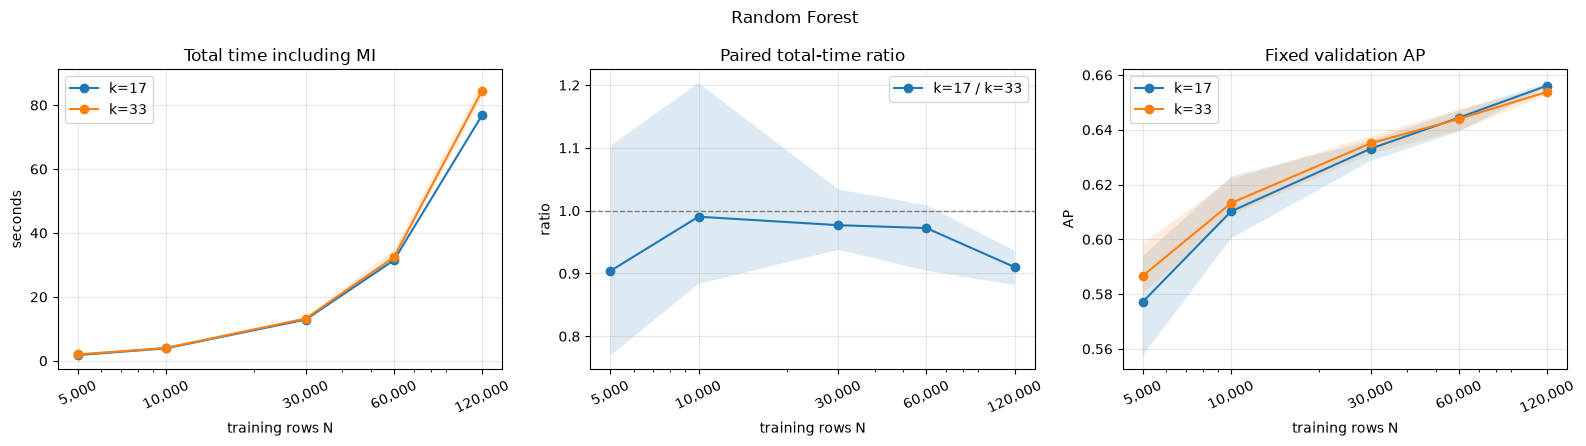

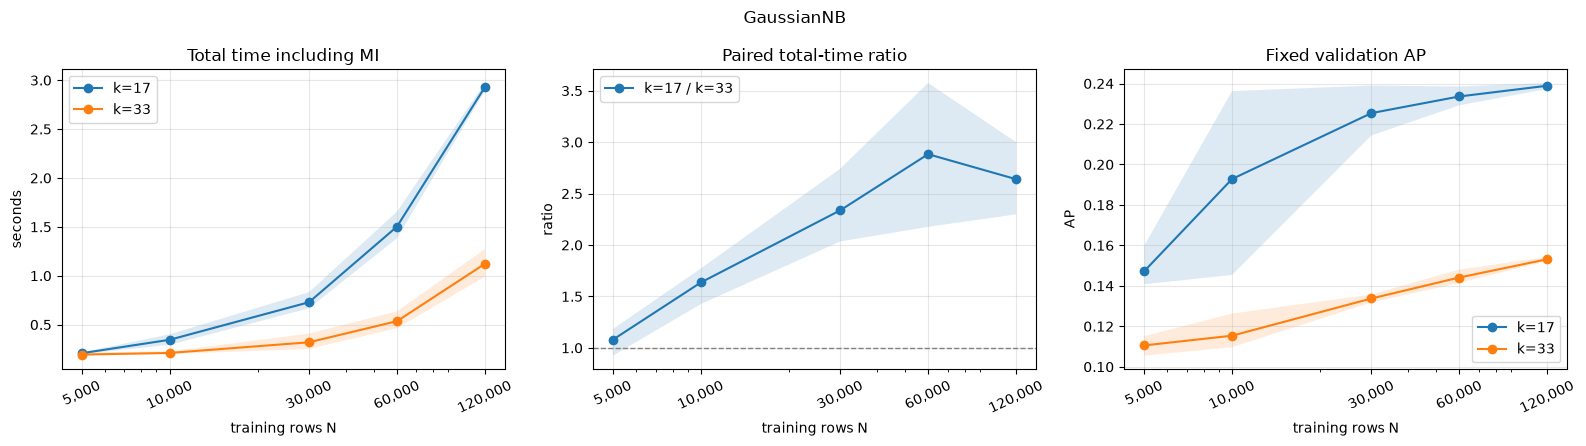

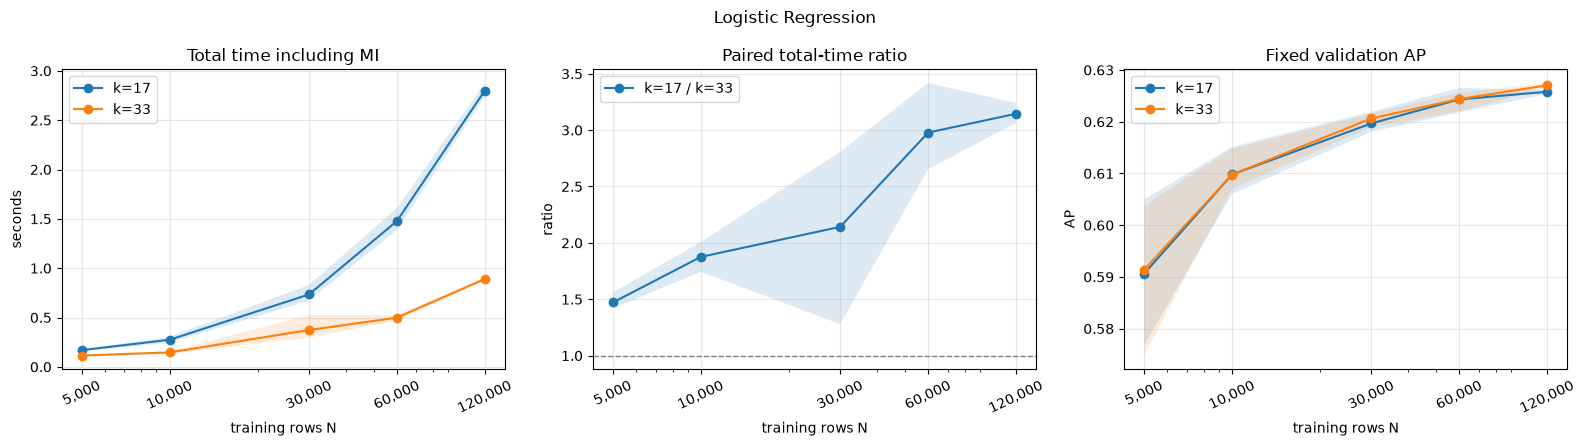

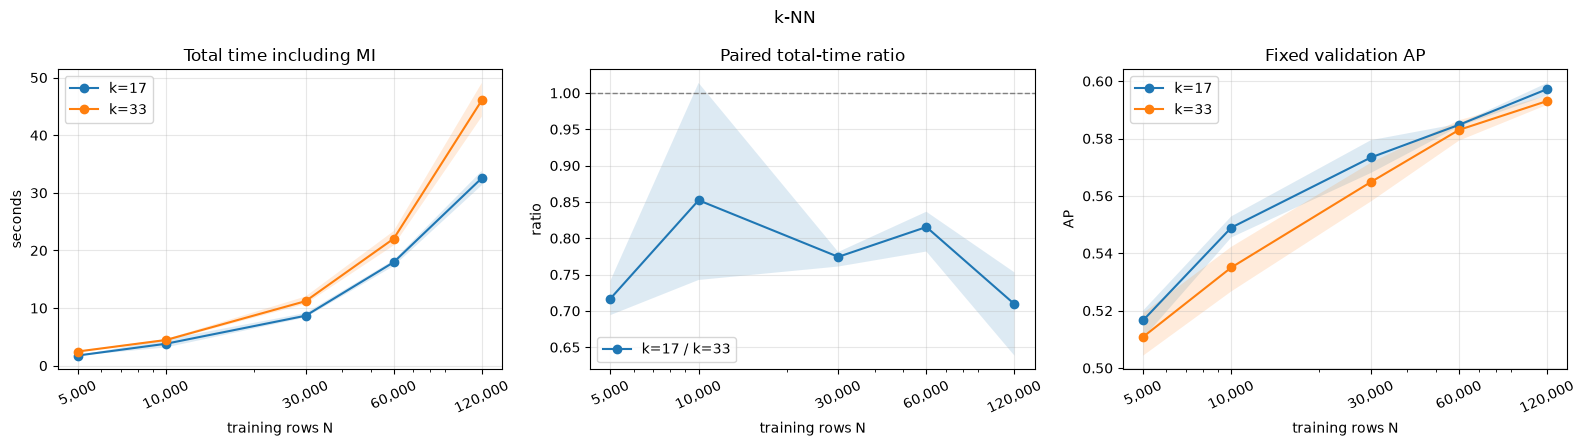

In [5]:
for model_name in MODELS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for k in FEATURE_COUNTS:
        group = summary.loc[(summary.model == model_name) & (summary.k == k)].sort_values("N")
        for ax, metric in [(axes[0], "total_seconds"), (axes[2], "AP")]:
            ax.plot(group.N, group[f"{metric}_mean"], marker="o", label=f"k={k}")
            ax.fill_between(group.N, group[f"{metric}_min"], group[f"{metric}_max"], alpha=0.15)
    group = ratio.loc[ratio.model == model_name].sort_values("N")
    axes[1].plot(group.N, group.total_ratio_mean, marker="o", label="k=17 / k=33")
    axes[1].fill_between(group.N, group.total_ratio_min, group.total_ratio_max, alpha=0.15)
    axes[1].axhline(1, color="grey", linestyle="--", linewidth=1)
    axes[0].set(title="Total time including MI", ylabel="seconds")
    axes[1].set(title="Paired total-time ratio", ylabel="ratio")
    axes[2].set(title="Fixed validation AP", ylabel="AP")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xticks(N_VALUES, [f"{n:,}" for n in N_VALUES])
        ax.set_xlabel("training rows N")
        ax.tick_params(axis="x", rotation=25)
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.suptitle(model_name)
    fig.tight_layout()
    plt.show()

## 6. Final checks and execution record

In [6]:
expected = set(product(N_VALUES, SEEDS, FEATURE_COUNTS, MODELS))
actual = set(runs[["N", "random_state", "k", "model"]].itertuples(index=False, name=None))
assert len(runs) == 120 and actual == expected
assert not runs.duplicated(["N", "random_state", "k", "model"]).any()
assert runs.validation_count.eq(20_000).all()
assert runs.validation_index_sha256.nunique() == 1
assert runs.training_count.eq(runs.N).all()
assert runs.loc[runs.k == 33, "MI_seconds"].eq(0).all()
assert runs.loc[runs.k == 17].groupby(["N", "random_state"]).MI_seconds.nunique().eq(1).all()
assert np.allclose(runs.total_seconds, runs[TIME_COLUMNS[:-1]].sum(axis=1))
assert runs[["TN", "FP", "FN", "TP"]].sum(axis=1).eq(20_000).all()
assert len(samples) == 15 and len(pd.concat(ranking_records)) == 495
assert samples.validation_overlap.eq(0).all() and samples.training_membership_verified.all()
assert np.all(np.abs(samples.sample_positive_rate - samples.pool_positive_rate) <= samples.rate_tolerance)
assert len(summary) == 40 and len(paired) == 60 and len(ratio) == 20
assert ratio.repetitions.eq(3).all() and mi_summary.repetitions.eq(3).all()
assert all(item["num_threads"] == 1 for item in threadpool_info())
assert make_classifier("Random Forest").get_params()["n_jobs"] == 1
assert make_classifier("k-NN").get_params()["n_jobs"] == 1
assert all(hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest for path, digest in input_hashes.items())
checkpoint()
execution_seconds = time.perf_counter() - experiment_started
lr_adjusted = runs.loc[(runs.model == "Logistic Regression") & (runs.max_iter > 100)]
pd.DataFrame([{"total_seconds": execution_seconds, "completed_runs": len(runs),
               "captured_fit_diagnostics": len(warning_records), "LR_adjusted_conditions": len(lr_adjusted),
               "python": platform.python_version(), "sklearn": sklearn.__version__,
               "pandas": pd.__version__, "numpy": np.__version__, "native_threads": 1}]).to_csv(
    results_dir / "trainsize_execution.csv", index=False
)
display(lr_adjusted[["N", "random_state", "k", "max_iter", "fit_attempts", "convergence_warning_count"]])
print("Final checks passed.")
print(f"Captured fit diagnostics: {len(warning_records)}")
print(f"Total execution time: {execution_seconds:.2f} seconds")

,N,random_state,k,max_iter,fit_attempts,convergence_warning_count
70,30000,2,33,200.0,2,1


Final checks passed.
Captured fit diagnostics: 1
Total execution time: 1256.09 seconds
